# Futsal AI — a visual walkthrough of your model
**Your existing best.pt → detections → ball search → player IDs → appearance clusters → court → radar.**

This notebook includes real, saved Spain–Portugal example outputs: pictures, player crops,
ball close-ups, cluster plots, tracking comparisons and a calibrated court preview. No weights
are embedded and no training runs. **Demo mode works without uploading a match or weights.**

For a new video: select a Colab **T4 GPU**, run setup, change `MODE` to `upload` or `drive`,
and run the cells in order. Use a short wide-view live-play interval first. Retained outputs
below belong to the recorded demo until you rerun the notebook with your own inputs.

An object detector does not automatically provide court keypoints. Court line proposals,
reviewed landmarks and optional separate keypoint-model output are shown as distinct stages.
Team clustering does not establish goalkeeper identity. Accuracy is reported only from labels.

In [1]:
import os, sys, io, json, base64, zipfile, tempfile, subprocess, uuid
from pathlib import Path
try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
PROJECT = Path('/content/futsal-ai-walkthrough') if IN_COLAB else Path(tempfile.gettempdir()) / 'futsal-ai-walkthrough'
PROJECT.mkdir(parents=True, exist_ok=True)
os.environ['YOLO_AUTOINSTALL'] = 'false'
SOURCE_BUNDLE = '...'
DEMO_BUNDLE = '...'

with zipfile.ZipFile(io.BytesIO(base64.b64decode(SOURCE_BUNDLE))) as archive:
    archive.extractall(PROJECT)
DEMO = PROJECT / 'walkthrough_demo'
DEMO.mkdir(exist_ok=True)
with zipfile.ZipFile(io.BytesIO(base64.b64decode(DEMO_BUNDLE))) as archive:
    archive.extractall(DEMO)
if IN_COLAB:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', '-e', str(PROJECT)+'[colab]'])
sys.path.insert(0, str(PROJECT / 'src'))
import cv2, numpy as np, pandas as pd, matplotlib
matplotlib.use('Agg')  # Explicit image display works in Colab and in the saved notebook.
import matplotlib.pyplot as plt
from IPython.display import display, Image, Video, Markdown
from futsal.video import frame_at, probe, load_image, save_image
from futsal.storage import load_tracks, sha256, write_json
from futsal.walkthrough import (overlay, team_overlay, crop_box, gather_crops, cluster_outfield,
                               goalkeeper_groups, track_diagnostics, TEAM_COLORS)
OUT = PROJECT / ('walkthrough_outputs_' + uuid.uuid4().hex[:8])
OUT.mkdir(exist_ok=True)

def show_figure(fig, name):
    path = OUT / (name + '.jpg')
    fig.savefig(path, dpi=115, bbox_inches='tight', facecolor='white', pil_kwargs={'quality':88, 'optimize':True})
    plt.close(fig)
    display(Image(filename=str(path)))

def image_grid(images, titles, name, columns=3, figsize=(16, 9)):
    if not images:
        print('No supported observations for this panel.'); return
    rows = int(np.ceil(len(images)/columns))
    fig, axes = plt.subplots(rows, columns, figsize=figsize, squeeze=False)
    fig.subplots_adjust(hspace=.55, wspace=.2)
    for ax, image, title in zip(axes.flat, images, titles):
        ax.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB)); ax.set_title(title, fontsize=10); ax.axis('off')
    for ax in list(axes.flat)[len(images):]: ax.axis('off')
    show_figure(fig, name)
print('Source and real demo evidence unpacked:', PROJECT)

Source and real demo evidence unpacked: C:\Users\User\AppData\Local\Temp\futsal-ai-walkthrough


## 1. Choose demo or your own match
`demo`: replay saved detections from the unchanged supplied model, without inference.
`upload`: upload best.pt and one MP4. `drive`: edit Drive paths. `local`: edit local paths.
All new analysis uses your selected checkpoint. Start defaults to 0, safely inside short videos.

In [2]:
MODE = 'demo'  # 'demo', 'upload', 'drive', 'local'
WEIGHTS_PATH = '/content/drive/MyDrive/FutsalAI/best.pt'
VIDEO_PATH = '/content/drive/MyDrive/FutsalAI/match.mp4'
START_S, DURATION_S, SAMPLE_FPS, IMGSZ = 0.0, 3.0, 20, 1280
EXTRA_BALL_SEARCH = False  # Same best.pt on crops; substantially slower.
DATA_YAML_PATH = ''  # Optional existing labeled validation/test set, never used for training.
if MODE == 'upload':
    from google.colab import files
    print('Upload best.pt, then one MP4 when prompted.')
    weights = files.upload()
    chosen = [n for n in weights if n.lower().endswith('.pt')]
    if len(chosen) != 1: raise ValueError('Upload exactly one checkpoint')
    WEIGHTS_PATH = str(Path(chosen[0]).resolve())
    del weights
    videos = files.upload()
    chosen = [n for n in videos if n.lower().endswith('.mp4')]
    if len(chosen) != 1: raise ValueError('Upload exactly one MP4')
    VIDEO_PATH = str(Path(chosen[0]).resolve())
    del videos
elif MODE == 'drive':
    from google.colab import drive
    drive.mount('/content/drive')
elif MODE not in {'demo', 'local'}:
    raise ValueError('Unknown input mode')
EVIDENCE = json.loads((DEMO / 'evidence.json').read_text('utf-8'))
if MODE != 'demo':
    if not Path(WEIGHTS_PATH).is_file() or not Path(VIDEO_PATH).is_file():
        raise FileNotFoundError('Edit WEIGHTS_PATH and VIDEO_PATH or select upload mode')
    video_info = probe(VIDEO_PATH)
    if not 0 <= START_S < video_info['duration_s']: raise ValueError('Start is outside the video')
    DURATION_S = min(DURATION_S, video_info['duration_s'] - START_S)
    SAMPLE_FPS = min(SAMPLE_FPS, video_info['average_fps'])
    print(video_info)
print('Mode:', MODE, '| Demo evidence:' if MODE == 'demo' else '| New input:',
      EVIDENCE['source_description'] if MODE == 'demo' else VIDEO_PATH)

Mode: demo | Demo evidence: Spain–Portugal, source 120–123 seconds


## 2. What is inside best.pt? How well is it doing?
Architecture, actual labels, parameters, training metadata and GPU checks are separate from
accuracy. Checkpoint-reported training metrics can be optimistic and do not evaluate a new match.
The demo metadata was inspected locally; it is not a fresh T4 benchmark.

In [3]:
import torch
from futsal.diagnostics import inspect_model
from ultralytics import YOLO
DEVICE = '0' if torch.cuda.is_available() else 'cpu'
if MODE == 'demo':
    MODEL_INFO = EVIDENCE['model']
else:
    inspected = YOLO(WEIGHTS_PATH)
    MODEL_INFO = inspect_model(inspected, WEIGHTS_PATH)
    if inspected.task != 'detect': raise ValueError('Primary checkpoint must be an object detector')
    del inspected
    if DEVICE != 'cpu': torch.cuda.empty_cache()
names = {int(k): v for k,v in MODEL_INFO['names'].items()}
display(pd.DataFrame([{'class_id':k, 'actual_checkpoint_label':v} for k,v in names.items()]))
print('Architecture:', MODEL_INFO['architecture'], '| Parameters:', f"{MODEL_INFO['parameters']:,}")
print('Training architecture:', MODEL_INFO['training_arguments'].get('model'))
print('Task:', MODEL_INFO['task'], '| Training version:', MODEL_INFO['checkpoint_ultralytics'])
print('Checkpoint SHA256:', MODEL_INFO['sha256'])
print('CURRENT runtime torch:', torch.__version__, '| CUDA:', torch.version.cuda, '| Device:', DEVICE)
if DEVICE != 'cpu':
    print('GPU:', torch.cuda.get_device_name(0), '| CUDA tensor check:', torch.ones(1, device='cuda').item())
print('Unsupported mixed classes:', MODEL_INFO.get('unsupported_classes'))
print('Checkpoint-reported metrics (not independent validation):', MODEL_INFO.get('checkpoint_reported_metrics'))
write_json(OUT / 'model_inspection.json', MODEL_INFO)

Architecture: DetectionModel | Parameters: 59,123,004
Training architecture: yolo12x.pt
Task: detect | Training version: 8.4.182
Checkpoint SHA256: e3d8d18b0461a93a80a7b9d627bc7bf7452e1e5f5d073395f92b646fc1c8415f
CURRENT runtime torch: 2.5.1+cu121 | CUDA: 12.1 | Device: 0
GPU: NVIDIA GeForce GTX 1650 Ti | CUDA tensor check: 1.0
Unsupported mixed classes: {'3': 'player- ball'}
Checkpoint-reported metrics (not independent validation): {'metrics/precision(B)': 0.89155, 'metrics/recall(B)': 0.87491, 'metrics/mAP50(B)': 0.94641, 'metrics/mAP50-95(B)': 0.72282, 'val/box_loss': 0.67088, 'val/cls_loss': 0.54173, 'val/dfl_loss': 0.9674, 'fitness': 0.72282}


,class_id,actual_checkpoint_label
0,0,ball
1,1,goalkeeper
2,2,player
3,3,player- ball


### Optional labeled evaluation — precision, recall and mAP
This runs `val()`, never training. Supply your existing data.yaml and labeled images on Drive;
check that its class names match the checkpoint. Use a held-out match for meaningful generalization.
Training-set scores and near-duplicate frames are not independent test evidence. This can take time.
When disabled, precision/recall/mAP remain unavailable instead of inferred from confidence scores.

In [4]:
RUN_LABELED_EVALUATION = False
EVALUATION_SPLIT = 'val'  # 'test' when an independent test set exists
evaluation = None
if RUN_LABELED_EVALUATION:
    if MODE == 'demo': raise ValueError('Select your weights and labeled dataset before evaluating')
    import yaml
    dataset = yaml.safe_load(Path(DATA_YAML_PATH).read_text('utf-8'))
    dataset_names = dataset['names']
    dataset_names = dict(enumerate(dataset_names)) if isinstance(dataset_names, list) else {int(k):v for k,v in dataset_names.items()}
    if dataset_names != names: raise ValueError('Dataset classes differ from checkpoint classes')
    evaluator = YOLO(WEIGHTS_PATH)
    measured = evaluator.val(data=DATA_YAML_PATH, split=EVALUATION_SPLIT, device=DEVICE,
        imgsz=IMGSZ, batch=1, workers=0, plots=True, project=str(OUT), name='labeled_evaluation')
    evaluation = measured.results_dict
    display(pd.DataFrame([evaluation]))
    print('Per-class mAP50–95:', dict(zip(measured.names.values(), measured.box.maps.tolist())))
    for name in ['confusion_matrix_normalized.png', 'BoxPR_curve.png', 'PR_curve.png']:
        path = Path(measured.save_dir) / name
        if path.exists(): display(Image(filename=str(path)))
    write_json(OUT / 'labeled_evaluation.json', {'split':EVALUATION_SPLIT, 'metrics':evaluation})
    del evaluator
    if DEVICE != 'cpu': torch.cuda.empty_cache()
else:
    display(pd.DataFrame({'metric':['precision','recall','mAP50','mAP50–95','IDF1','HOTA'],
        'value':['Unavailable — labeled evaluation not run']*6}))

,metric,value
0,precision,Unavailable — labeled evaluation not run
1,recall,Unavailable — labeled evaluation not run
2,mAP50,Unavailable — labeled evaluation not run
3,mAP50–95,Unavailable — labeled evaluation not run
4,IDF1,Unavailable — labeled evaluation not run
5,HOTA,Unavailable — labeled evaluation not run


## 3. Run detection and tracking, or replay measured demo evidence
New-video mode exports a short raw-class detection video followed by the same motion-aware
pipeline as the application. This includes BoT-SORT, 2-observation starts, low-score recovery,
separate ball confirmation and display-only smoothing. No missing positions are invented.
The mixed `player- ball` class is shown in raw diagnostics but excluded from tactical roles.

In [5]:
import uuid
from futsal.config import RunConfig
from futsal.pipeline import run_pipeline
from futsal.diagnostics import detection_check
from futsal.models import Detector
from futsal.quality import summarize_run
if MODE == 'demo':
    RECORDS, FRAME_DIR = EVIDENCE['frames'], DEMO
    tracks = pd.read_json(DEMO / 'motion_tracks.json')
    ball_tracks = pd.read_json(DEMO / 'ball_tracks.json')
    baseline_tracks = pd.read_json(DEMO / 'baseline_tracks.json')
    RUN_DIR = None
    print('Recorded inference only; live inference speed is not measured by replay.')
else:
    attempt = uuid.uuid4().hex[:8]
    RAW_DIR = OUT / ('raw_' + attempt)
    raw_report = detection_check(VIDEO_PATH, WEIGHTS_PATH, RAW_DIR, start=START_S,
        duration=DURATION_S, fps=SAMPLE_FPS, imgsz=IMGSZ, device=DEVICE, confidence=.15)
    display(Image(filename=str(RAW_DIR / 'representative_frames.jpg')))
    display(Video(str(RAW_DIR / 'detections.mp4'), embed=True, width=900))
    config = RunConfig(model=WEIGHTS_PATH, device=DEVICE, imgsz=IMGSZ,
        start=START_S, duration=DURATION_S, sample_fps=SAMPLE_FPS,
        tracker='botsort', confidence=.05, person_confidence=.05, ball_confidence=.05,
        track_low_threshold=.05, track_high_threshold=.25, track_new_threshold=.35,
        track_buffer_seconds=1.5, track_min_observations=2, smooth_boxes=True,
        ball_confirmation_frames=2, ball_start_confidence=.20, ball_max_gap=.25,
        tile_ball=EXTRA_BALL_SEARCH, team_mode='color', radar=False)
    RUN_DIR = OUT / ('run_' + attempt)
    run_pipeline(VIDEO_PATH, RUN_DIR, config)
    tracks = load_tracks(RUN_DIR)
    ball_tracks = tracks
    baseline_tracks = pd.DataFrame()
    log = [json.loads(line) for line in (RUN_DIR / 'detections.jsonl').read_text().splitlines()]
    FRAME_DIR = OUT / ('frames_' + attempt)
    FRAME_DIR.mkdir()
    RECORDS = []
    detector = Detector(WEIGHTS_PATH, DEVICE, IMGSZ, .05)
    detector.configure(config)
    for index in np.unique(np.linspace(0,len(log)-1,min(10,len(log))).astype(int)):
        row = log[index]
        image = frame_at(VIDEO_PATH,row['time_s'])
        name = f'{index:04d}.jpg'
        save_image(FRAME_DIR / name, image)
        # Same-weight full-frame view for the ball comparison; stored pipeline may include crops.
        full = detector.predict(image)
        RECORDS.append({**row, 'image':name, 'full_frame_detections':full})
    del detector
    if DEVICE != 'cpu': torch.cuda.empty_cache()
    print(summarize_run(RUN_DIR))
if not RECORDS: raise ValueError('No sampled source frames; choose another interval')
sample = RECORDS[0]
image = load_image(FRAME_DIR / sample['image'])
print('Display frames:',len(RECORDS),'| Accepted observations:',len(tracks))

Recorded inference only; live inference speed is not measured by replay.
Display frames: 10 | Accepted observations: 604


## 4. Player detection pictures — boxes, labels, confidences
Colors here distinguish boxes from the background, not real kit colors. Watch for missed distant
players, overlapping boxes and role errors. A high confidence score is not proof of correctness.

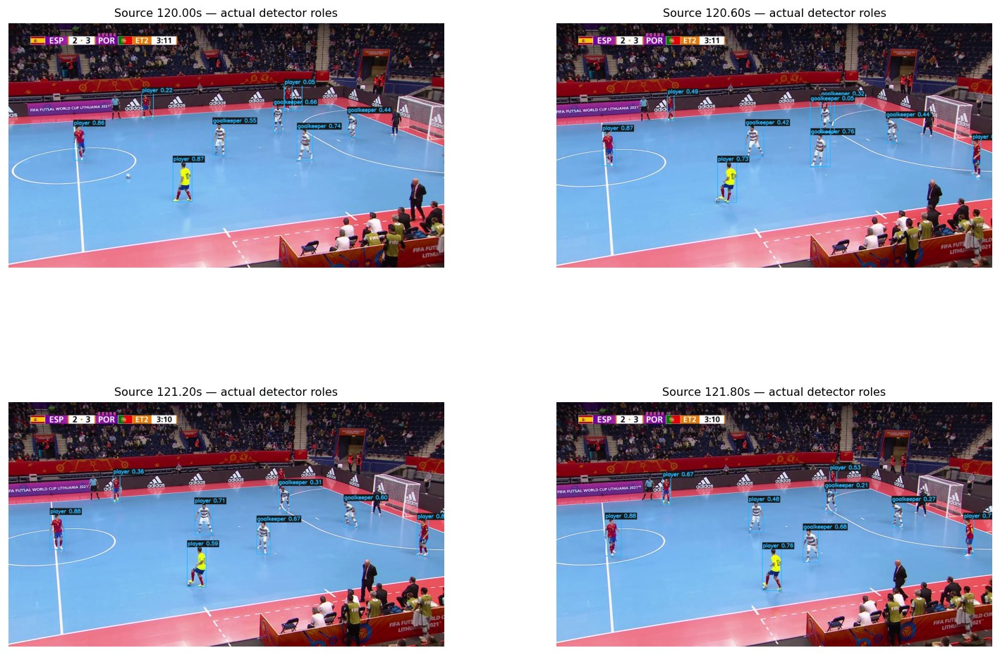

,candidates_in_display_frames
player,51
goalkeeper,38
ball,8


In [6]:
selected = RECORDS[::max(1,len(RECORDS)//4)][:4]
image_grid([overlay(load_image(FRAME_DIR/r['image']),r['detections'],'person') for r in selected],
    [f"Source {r['time_s']:.2f}s — actual detector roles" for r in selected],
    'player_detections',columns=2,figsize=(16,10))
observed_counts = pd.Series([d['model_class'] for r in RECORDS for d in r['detections']]).value_counts()
display(observed_counts.rename('candidates_in_display_frames').to_frame())

## 5. Ball detection — full-frame view, crop search and close-ups
The ball detector is still best.pt. Larger ball crops can recover small objects but also produce
false positives. Temporal confirmation and duplicate suppression filter candidates separately
from players. The demo compares the same frames, with and without extra ball search.

Coverage measures availability, not precision, recall or ball accuracy.


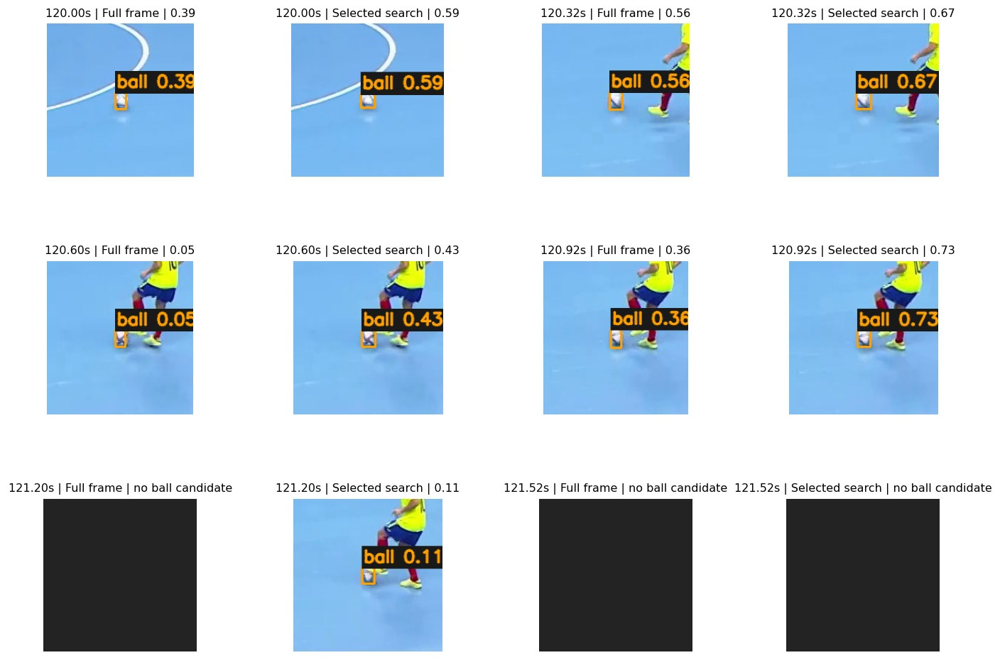

,search,accepted_frames,same_sampled_frames,processing_fps_local
0,Full frame,5,30,1.2387
1,Extra crops,17,30,0.2747


In [7]:
ball_images, ball_titles = [], []
for r in RECORDS[:6]:
    full = [d for d in r['full_frame_detections'] if d['class_name']=='ball']
    searched = [d for d in r['detections'] if d['class_name']=='ball']
    source_image = load_image(FRAME_DIR/r['image'])
    for label, candidates in [('Full frame',full), ('Selected search',searched)]:
        if candidates:
            candidate = max(candidates,key=lambda d:d['score'])
            close = crop_box(overlay(source_image,[candidate]),candidate['box'],pad=90)
            ball_images.append(close)
            ball_titles.append(f"{r['time_s']:.2f}s | {label} | {candidate['score']:.2f}")
        else:
            ball_images.append(np.full((180,180,3),35,np.uint8))
            ball_titles.append(f"{r['time_s']:.2f}s | {label} | no ball candidate")
image_grid(ball_images,ball_titles,'ball_closeups',columns=4,figsize=(15,10))
if MODE=='demo':
    display(pd.DataFrame({'search':['Full frame','Extra crops'], 'accepted_frames':[5,17],
        'same_sampled_frames':[30,30], 'processing_fps_local':[1.2387,.2747]}))
    display(Video(str(DEMO/'ball_before_after.mp4'),embed=True,width=1000))
else:
    print('Extra ball crops enabled:',EXTRA_BALL_SEARCH)
    print('No paired speed/accuracy comparison is claimed for this new run.')
print('Coverage measures availability, not precision, recall or ball accuracy.')

## 6. How we assign outfield players to teams
First inspect the crops. We take the central upper-body jersey region, compute a robust LAB
color feature and fit two K-Means clusters using only detector-labeled outfield players.
The blue/red colors are A/B display labels. Distant or ambiguous samples remain unknown.
The pipeline adds a temporal vote per track; the plot below explains the underlying prototypes.

{'status': 'unverified_appearance_clusters', 'silhouette': 0.873737396876328, 'accepted_crops': 41, 'accuracy': None}
Silhouette is cluster separation; team accuracy needs manually labeled identities.


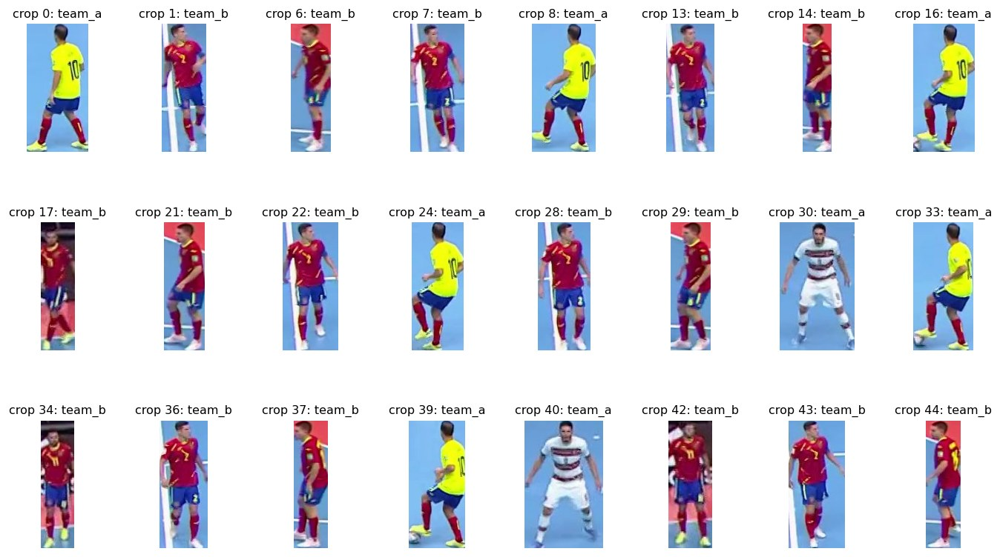

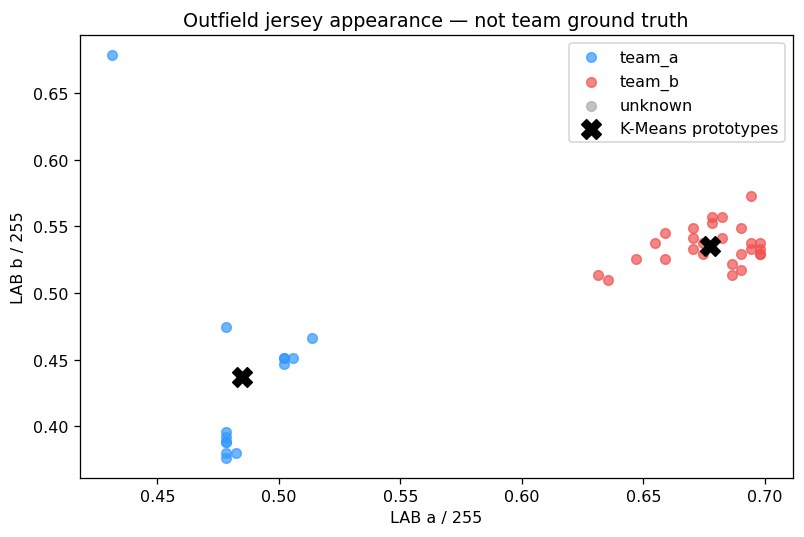

,time_s,model_class,score,team,cluster_margin
0,120.00,player,0.869163,team_a,0.445347
1,120.00,player,0.859976,team_b,0.436449
2,120.00,goalkeeper,0.737418,unknown,NaN
3,120.00,goalkeeper,0.659130,unknown,NaN
4,120.00,goalkeeper,0.554088,unknown,NaN
5,120.00,goalkeeper,0.438398,unknown,NaN
6,120.32,player,0.867184,team_b,0.435811
7,120.32,player,0.853045,team_b,0.435822
8,120.32,player,0.790162,team_a,0.445347
9,120.32,goalkeeper,0.706020,unknown,NaN


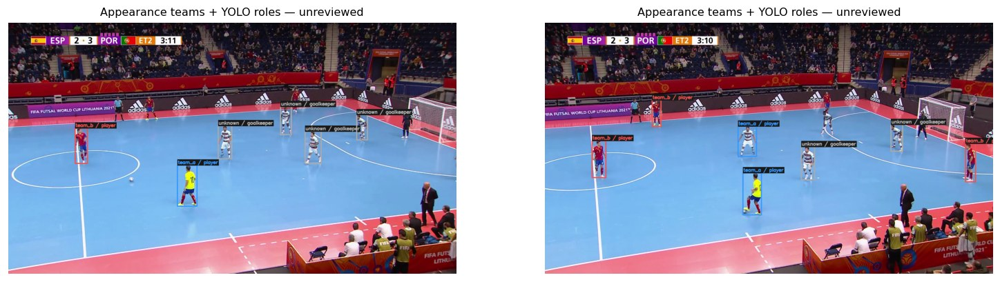

In [8]:
crop_rows, crops = gather_crops(RECORDS,FRAME_DIR)
if crop_rows.empty:
    clustered, cluster_model, cluster_report = crop_rows, None, {'status':'no_usable_crops'}
    print('No usable person crops; team and goalkeeper panels remain unavailable.')
else:
    clustered, cluster_model, cluster_report = cluster_outfield(crop_rows)
    eligible = clustered.index[clustered.role.eq('outfield_player')].tolist()
    image_grid([crops[i] for i in eligible[:24]],
        [f"crop {i}: {clustered.loc[i,'team']}" for i in eligible[:24]],
        'outfield_crops',columns=8,figsize=(15,8))
    if eligible:
        features = np.asarray(clustered.loc[eligible,'feature'].tolist())
        fig, ax = plt.subplots(figsize=(8,5))
        for team,color in TEAM_COLORS.items():
            keep = clustered.loc[eligible,'team'].eq(team).to_numpy()
            ax.scatter(features[keep,1],features[keep,2],c=color,label=team,alpha=.7)
        if cluster_model is not None:
            centers = cluster_model.cluster_centers_
            ax.scatter(centers[:,1],centers[:,2],c='black',marker='X',s=150,label='K-Means prototypes')
        ax.set(xlabel='LAB a / 255',ylabel='LAB b / 255',title='Outfield jersey appearance — not team ground truth')
        ax.legend(); show_figure(fig,'team_clusters')
    display(clustered[['time_s','model_class','score','team','cluster_margin']].head(16))
    print(cluster_report)
    preview_records = RECORDS[::max(1,len(RECORDS)//2)][:2]
    image_grid([team_overlay(load_image(FRAME_DIR/r['image']),clustered[np.isclose(clustered.time_s,r['time_s'])])
                for r in preview_records],
               ['Appearance teams + YOLO roles — unreviewed']*len(preview_records),
               'team_assignment_overlays',columns=2,figsize=(16,7))
print('Silhouette is cluster separation; team accuracy needs manually labeled identities.')

### Optional tutorial-style SigLIP → UMAP → K-Means
LAB is the active baseline. This optional comparison downloads an **appearance encoder**, not
a new object detector. Review the groups and map A/B manually. Unsupervised separation is not
team accuracy. It can be memory-intensive; the YOLO detector is released before embedding.

In [9]:
RUN_SIGLIP_COMPARISON = False
if RUN_SIGLIP_COMPARISON and not crop_rows.empty:
    subprocess.check_call([sys.executable,'-m','pip','install','-q','-e',str(PROJECT)+'[embeddings]'])
    import umap
    from sklearn.cluster import KMeans
    from futsal.team_comparison import siglip_embeddings
    indexes = crop_rows.index[crop_rows.role.eq('outfield_player')].tolist()
    if len(indexes)<12: raise ValueError('Need at least 12 usable outfield crops')
    embeddings = siglip_embeddings([crops[i] for i in indexes],device='cuda' if DEVICE!='cpu' else 'cpu')
    reduced = umap.UMAP(n_components=3,n_neighbors=min(15,len(indexes)-1),random_state=42).fit_transform(embeddings)
    labels = KMeans(2,n_init=10,random_state=42).fit_predict(reduced)
    fig,ax = plt.subplots(figsize=(8,5))
    ax.scatter(reduced[:,0],reduced[:,1],c=labels,cmap='coolwarm')
    ax.set(title='SigLIP → UMAP → K-Means: unreviewed appearance groups',xlabel='UMAP 1',ylabel='UMAP 2')
    show_figure(fig,'siglip_clusters')
    image_grid([crops[i] for i in indexes[:24]], [f'appearance group {g}' for g in labels[:24]],
               'siglip_crops',columns=8,figsize=(15,8))
else:
    print('Optional SigLIP comparison disabled; no appearance weights downloaded.')

Optional SigLIP comparison disabled; no appearance weights downloaded.


## 7. Goalkeepers — role prediction, kit clustering and manual correction
**Role and team are different questions.** YOLO predicts the goalkeeper label. Clustering
can show goalkeeper *kit groups*, but kit group 0/1 cannot be equated to Team A/B: their shirts
often differ from outfield kits. We therefore keep their team unknown until reviewed.

Inspect the following goalkeeper-labeled crops. The saved demo includes white-shirt outfield
players mislabeled as goalkeepers. That is a detector error, not evidence of several real
goalkeepers. No referee role is invented for a checkpoint without that class. In future,
goal-area position and temporal context can support reviewed proposals, including flying GKs.

For persistent corrections, use the application track-level team/role review tools.


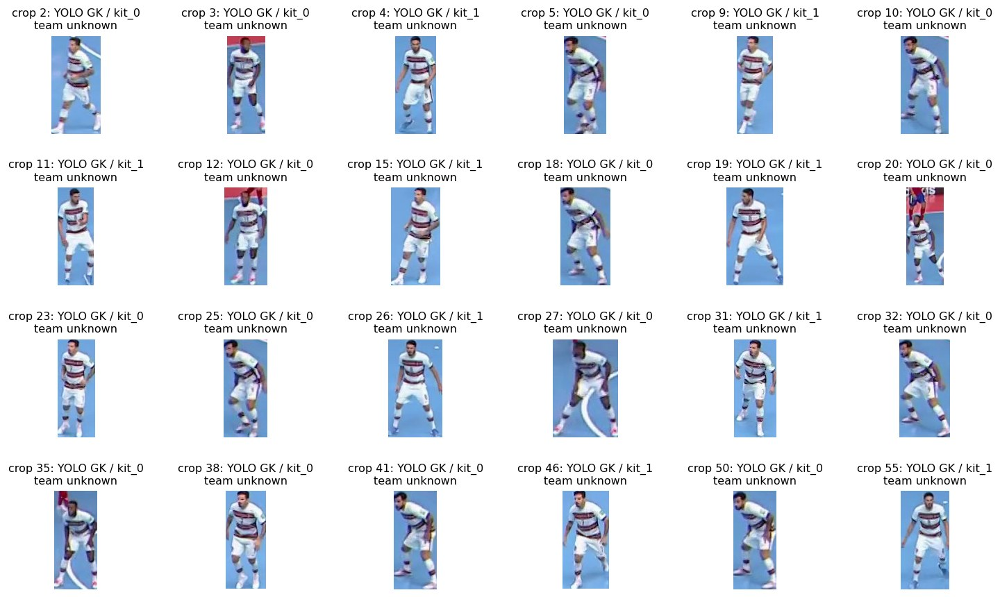

,time_s,model_class,score,kit_group,team
2,120.00,goalkeeper,0.737418,kit_0,unknown
3,120.00,goalkeeper,0.659130,kit_0,unknown
4,120.00,goalkeeper,0.554088,kit_1,unknown
5,120.00,goalkeeper,0.438398,kit_0,unknown
9,120.32,goalkeeper,0.706020,kit_1,unknown
10,120.32,goalkeeper,0.674289,kit_0,unknown
11,120.32,goalkeeper,0.472810,kit_1,unknown
12,120.32,goalkeeper,0.375802,kit_0,unknown
15,120.60,goalkeeper,0.762326,kit_1,unknown
18,120.60,goalkeeper,0.442000,kit_0,unknown


In [10]:
if not crop_rows.empty:
    gk = goalkeeper_groups(clustered)
    indexes = gk.index.tolist()[:24]
    image_grid([crops[i] for i in indexes],
        [f"crop {i}: YOLO GK / {gk.loc[i,'kit_group']}\nteam unknown" for i in indexes],
        'goalkeeper_candidates',columns=6,figsize=(16,9))
    display(gk[['time_s','model_class','score','kit_group','team']].head(16))
    # Corrections apply ONLY to the specified displayed crops, not all frames or identities.
    # Example syntax: {crop_index: {'role':'outfield_player','team':'team_a'}}
    CROP_CORRECTIONS = {}
    reviewed_crops = clustered.copy()
    for index,correction in CROP_CORRECTIONS.items():
        if index not in reviewed_crops.index: raise ValueError('Unknown displayed crop index')
        if correction.get('team','unknown') not in TEAM_COLORS: raise ValueError('Invalid team')
        for key,value in correction.items():
            if key not in {'role','team'}: raise ValueError('Only role/team corrections supported here')
            reviewed_crops.loc[index,key] = value
    reviewed_crops.drop(columns=['feature']).to_json(OUT/'crop_review.json',orient='records',indent=2)
    print('For persistent corrections, use the application track-level team/role review tools.')

## 8. How tracking works — persistent local IDs, gaps and smoothing
Detection boxes feed BoT-SORT's motion prediction and association. Low-score detections may
recover an existing ID; new IDs require stronger evidence and two observations. Camera cuts
reset IDs. Temporary disappearance does not guarantee identity recovery. Ball association is
separate. Only overlays are smoothed; exported raw boxes remain available for analytics.

The plots show observation timelines and image-space footpoint paths. Gaps are left blank.
These are not meter trajectories, speeds or ID-switch accuracy measurements.

Tracklet count is a fragmentation diagnostic; IDF1, HOTA and ID switches need identity labels.


,observations,first_s,last_s,observed_span_s
tracklet_id,,,,
tracker_comparison:motion_confirmed:s0:p2,78,120.12,123.96,3.84
tracker_comparison:motion_confirmed:s0:p5,77,120.12,123.96,3.84
tracker_comparison:motion_confirmed:s0:p7,77,120.12,123.96,3.84
tracker_comparison:motion_confirmed:s0:p6,76,120.16,123.96,3.80
tracker_comparison:motion_confirmed:s0:p1,74,120.12,123.76,3.64
tracker_comparison:motion_confirmed:s0:p3,74,120.12,123.96,3.84
tracker_comparison:motion_confirmed:s0:p10,64,120.56,123.96,3.40
tracker_comparison:motion_confirmed:s0:p12,45,121.00,123.96,2.96
tracker_comparison:motion_confirmed:s0:p4,11,120.12,120.60,0.48


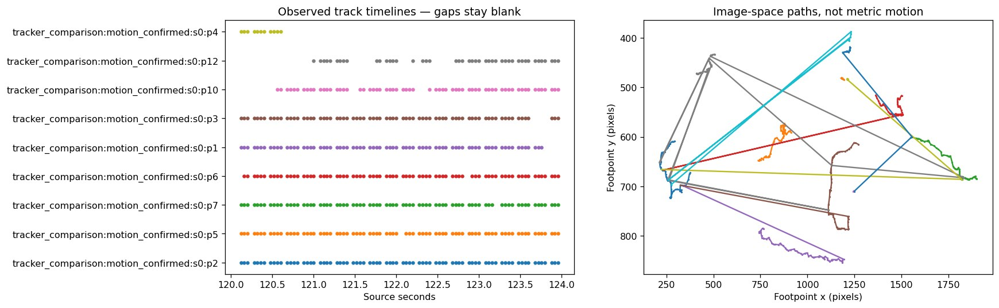

,same_80_frames,tracklets
0,ByteTrack baseline,11
1,BoT-SORT + confirmation,9


In [11]:
diagnostics = track_diagnostics(tracks)
display(diagnostics.head(15))
if not diagnostics.empty:
    ids = diagnostics.index[:12]
    people = tracks[tracks.class_name.eq('person') & tracks.tracklet_id.isin(ids)]
    fig,axes = plt.subplots(1,2,figsize=(15,5))
    for j,identity in enumerate(ids):
        part = people[people.tracklet_id.eq(identity)].sort_values('time_s')
        axes[0].scatter(part.time_s,np.full(len(part),j),s=9)
        x = ((part.x1+part.x2)/2).to_numpy(float); y = part.y2.to_numpy(float)
        times = part.time_s.to_numpy(float)
        for segment in np.split(np.arange(len(part)),np.flatnonzero(np.diff(times)>.25)+1):
            axes[1].plot(x[segment],y[segment],'.-',markersize=2)
    axes[0].set_yticks(range(len(ids)),ids); axes[0].set(xlabel='Source seconds',title='Observed track timelines — gaps stay blank')
    axes[1].invert_yaxis(); axes[1].set(xlabel='Footpoint x (pixels)',ylabel='Footpoint y (pixels)',title='Image-space paths, not metric motion')
    show_figure(fig,'tracking_diagnostics')
if MODE=='demo':
    display(pd.DataFrame({'same_80_frames':['ByteTrack baseline','BoT-SORT + confirmation'],
        'tracklets':[len(track_diagnostics(baseline_tracks)),len(diagnostics)]}))
    display(Video(str(DEMO/'tracking_before_after.mp4'),embed=True,width=1000))
elif RUN_DIR:
    display(Video(str(RUN_DIR/'annotated.mp4'),embed=True,width=1000))
print('Tracklet count is a fragmentation diagnostic; IDF1, HOTA and ID switches need identity labels.')

## 9. Court line candidates and keypoints
The supplied best.pt is a detection model and has no semantic court keypoint head.
OpenCV's white-line/Hough output below is a baseline of **line candidates**, including false
positives from boards, logos and other sport markings. Intersections are not automatically
named futsal landmarks. The next section shows actual reviewed calibration points separately.
An optional accepted futsal keypoint checkpoint can be supplied without modifying best.pt.

Line proposals: 40 | Semantic court keypoints from best.pt: unsupported
No separate court keypoint detector supplied; automatic semantic keypoints unavailable.


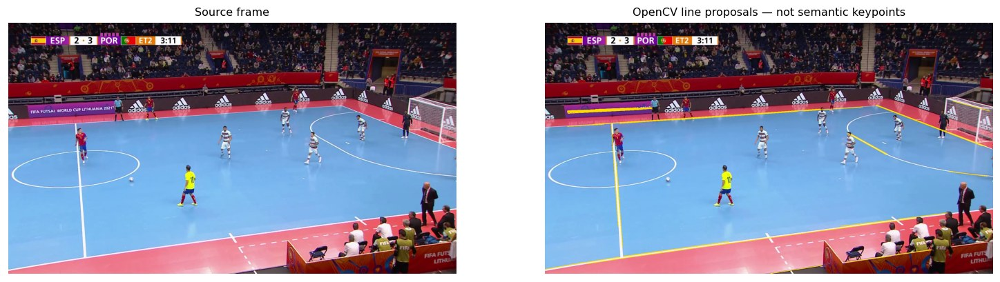

In [12]:
from futsal.court import line_candidates, CourtLandmarkDetector
court_image = image.copy()
lines = line_candidates(image)
for x1,y1,x2,y2 in lines:
    cv2.line(court_image,(x1,y1),(x2,y2),(0,220,255),2)
image_grid([image,court_image],['Source frame','OpenCV line proposals — not semantic keypoints'],
           'court_line_candidates',columns=2,figsize=(16,7))
print('Line proposals:',len(lines),'| Semantic court keypoints from best.pt: unsupported')
COURT_MODEL_PATH = ''
COURT_SCHEMA_PATH = ''
model_anchor = None
if COURT_MODEL_PATH:
    detector = CourtLandmarkDetector(COURT_MODEL_PATH,COURT_SCHEMA_PATH,device=DEVICE)
    model_anchor = detector.propose(image,sample['time_s'])
    print('Separate court model proposal:',model_anchor)
    if model_anchor:
        proposal_image = image.copy()
        for point in model_anchor.image_points + model_anchor.validation_image_points:
            cv2.circle(proposal_image,tuple(np.rint(point).astype(int)),6,(255,0,255),-1)
        image_grid([proposal_image],['Separate court-model proposals — acceptance still required'],
                   'court_model_proposals',columns=1,figsize=(12,7))
else:
    print('No separate court keypoint detector supplied; automatic semantic keypoints unavailable.')

## 10. Named landmarks → homography → player footpoints on the court
The demo has four manually reviewed floor landmarks and two distinct check points at source
120s. Red points fit the homography; yellow points validate it. RANSAC rejects inconsistent
fits. The court overlay and top-down player positions below use that **single frame only**.
It must never be reused blindly after camera motion or on a different video.

40×20 m dimensions are assumed here, not independently measured. Reprojection error in pixels
does not establish real-world positional accuracy. Metric movement remains disabled.

{'valid': True, 'error_px': 3.6379064318804186, 'anchor_validation_error_px': 3.6379064318804186, 'inliers': 4, 'fit_median_px': 7.031142602530156e-13, 'scale_verified': False, 'reason': 'accepted', 'direction': 'image_to_court', 'units': 'assumed_m'}
Ball is excluded from this radar: airborne-ball image centers are not floor coordinates.


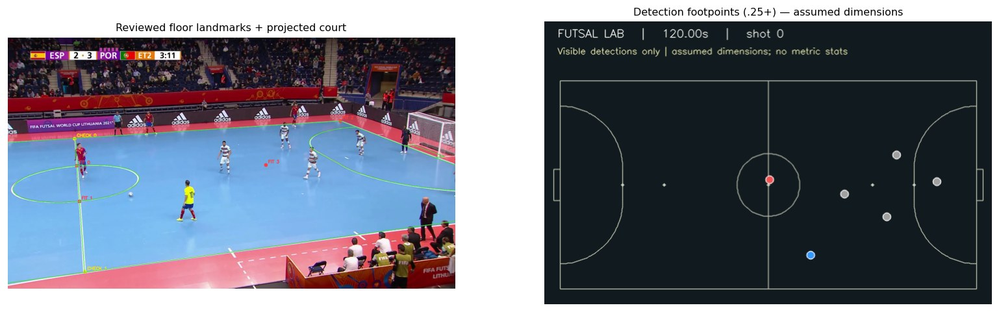

,court_x,court_y,calibration_valid,class_name,role,team,tracklet_id
0,24.058667,16.739185,True,person,outfield_player,team_a,None
1,20.141304,9.474459,True,person,outfield_player,team_b,None
2,31.362280,13.068931,True,person,goalkeeper,unknown,None
3,32.340019,7.140661,True,person,goalkeeper,unknown,None
4,27.334054,10.901875,True,person,goalkeeper,unknown,None
5,36.170836,9.670209,True,person,goalkeeper,unknown,None


,landmark,use,image_xy,court_xy_assumed_m
0,circle_far,fit,"[296.0, 552.0]","[20.0, 7.0]"
1,circle_near,fit,"[307.0, 705.0]","[20.0, 13.0]"
2,corner_right_far,fit,"[1426.0, 360.0]","[40.0, 0.0]"
3,second_penalty_right,fit,"[1107.0, 549.0]","[30.0, 10.0]"
4,halfway_far,independent check,"[286.0, 436.0]","[20.0, 0.0]"
5,halfway_near,independent check,"[331.0, 1007.0]","[20.0, 20.0]"


In [13]:
from futsal.geometry import CalibrationSpec, fit_calibration, project
from futsal.radar import court_paths, RadarRenderer
from futsal.notebook_ui import pick_calibration, named_landmarks
CALIBRATION_JSON = ''  # Optional anchors for YOUR video, never the demo anchor on a new match.
PICK_MY_CALIBRATION = False  # Colab interactive picker: 4+ fit + 1+ distinct check point.
MANUAL_POINTS_REVIEWED = False
anchor = None
if MODE=='demo':
    if abs(sample['time_s']-EVIDENCE['calibration']['time_s'])>1e-6:
        raise ValueError('Demo calibration belongs only to its anchor frame')
    anchor = CalibrationSpec.model_validate(EVIDENCE['calibration'])
elif CALIBRATION_JSON:
    anchors = json.loads(Path(CALIBRATION_JSON).read_text('utf-8'))
    candidates = [a for a in anchors if abs(a['time_s']-sample['time_s'])<.04 and a.get('source_sha256')==sha256(VIDEO_PATH)]
    if candidates: anchor = CalibrationSpec.model_validate(candidates[0])
    else: print('No matching source-bound anchor at this frame; not reusing stale calibration.')
elif PICK_MY_CALIBRATION:
    anchor = pick_calibration(image,sample['time_s'])
    anchor = anchor.model_copy(update={'reviewed':MANUAL_POINTS_REVIEWED,'source_sha256':sha256(VIDEO_PATH)})
elif model_anchor:
    anchor = model_anchor
calibration_quality = {'valid':False,'reason':'no_validated_correspondences'}
radar_rows = []
if anchor:
    matrix,calibration_quality = fit_calibration(anchor)
    labelled = image.copy()
    for prefix,points,color in [('FIT',anchor.image_points,(60,60,255)),('CHECK',anchor.validation_image_points,(0,230,255))]:
        for j,point in enumerate(points):
            p = tuple(np.rint(point).astype(int)); cv2.circle(labelled,p,8,color,-1)
            cv2.putText(labelled,f'{prefix} {j}',(p[0]+10,p[1]-8),0,.6,color,2)
    if calibration_quality['valid']:
        paths,_ = court_paths(anchor.length,anchor.width)
        for path in paths:
            projected = project(np.linalg.inv(matrix),path)
            if np.isfinite(projected).all() and np.abs(projected).max()<1e6:
                cv2.polylines(labelled,[np.rint(projected).astype(np.int32)],False,(70,220,70),2)
        for j,d in enumerate(sample['detections']):
            if d['class_name']!='person' or d['score']<.25: continue
            foot = [(d['box'][0]+d['box'][2])/2,d['box'][3]]
            point = project(matrix,[foot])[0]
            team = 'unknown'
            if cluster_model is not None and d['role']=='outfield_player':
                from futsal.teams import jersey_feature
                feature = jersey_feature(image,d['box'])
                if feature is not None:
                    distances = np.linalg.norm(cluster_model.cluster_centers_-feature,axis=1)
                    if distances.min()<=.28 and abs(distances[0]-distances[1])>=.05:
                        team = ['team_a','team_b'][np.argmin(distances)]
            radar_rows.append({'court_x':float(point[0]),'court_y':float(point[1]),'calibration_valid':True,
                'class_name':'person','role':d['role'],'team':team,'tracklet_id':None})
    radar = RadarRenderer(anchor.length,anchor.width,show_ids=False).render(radar_rows,sample['time_s'],0,calibration_quality)
    image_grid([labelled,radar],['Reviewed floor landmarks + projected court','Detection footpoints (.25+) — assumed dimensions'],
               'landmarks_and_radar',columns=2,figsize=(17,7))
    display(pd.DataFrame(radar_rows))
    semantic_names = named_landmarks(anchor.length,anchor.width)
    point_names = [next((name for name,xy in semantic_names.items() if np.allclose(xy,point)),'custom floor point')
                   for point in anchor.court_points+anchor.validation_court_points]
    display(pd.DataFrame({'landmark':point_names,
        'use':['fit']*len(anchor.image_points)+['independent check']*len(anchor.validation_image_points),
        'image_xy':anchor.image_points+anchor.validation_image_points,
        'court_xy_assumed_m':anchor.court_points+anchor.validation_court_points}))
else:
    print('Select reviewed floor landmarks before showing player positions on a new match.')
print(calibration_quality)
print('Ball is excluded from this radar: airborne-ball image centers are not floor coordinates.')
write_json(OUT/'calibration_quality.json',calibration_quality)

## 11. What is validated, and what remains unknown?
The saved demo demonstrates execution and observed coverage, not production reliability.
The supplied wooden-court download.mp4 still produced no accepted tracks in a 280-frame run;
neither crop tuning nor testing the checkpoint's exact training version solved that failure.
Goalkeeper role confusion is visible above. Weak detection cannot be repaired by changing IDs.

To quantify quality, use held-out labeled detection frames, reviewed team/role labels and
identity trajectories for IDF1/HOTA. Court keypoint error requires labeled landmarks; metric
position and speed require verified geometry. Confidence, silhouette and tracklet counts
must not be substituted for those measurements.

In [14]:
if MODE=='demo':
    display(pd.DataFrame([
        {'check':'Extra ball search, same 30 frames','observed_result':'5 → 17 accepted ball frames','accuracy_measured':False},
        {'check':'Tracker, same 80 frames and detections','observed_result':'11 → 9 tracklets','accuracy_measured':False},
        {'check':'Uploaded wooden-court clip','observed_result':'280 frames; 23 weak person candidates; 0 tracks','accuracy_measured':False},
        {'check':'Manual demo calibration','observed_result':str(calibration_quality.get('error_px'))+' px independent check error','accuracy_measured':False},
    ]))
else:
    print(summarize_run(RUN_DIR))
print('Fresh labeled detector evaluation:',evaluation if evaluation is not None else 'not run')

Fresh labeled detector evaluation: not run


,check,observed_result,accuracy_measured
0,"Extra ball search, same 30 frames",5 → 17 accepted ball frames,False
1,"Tracker, same 80 frames and detections",11 → 9 tracklets,False
2,Uploaded wooden-court clip,280 frames; 23 weak person candidates; 0 tracks,False
3,Manual demo calibration,3.6379064318804186 px independent check error,False


## 12. Export the analysis, pictures and videos
Keep timestamps and actual class names. Unknown values remain empty. Review corrections are
exported separately. For long videos and verified tracking/calibration, use the application
or the companion pipeline notebook. Tactical events are not inferred by this visual walkthrough.

In [15]:
import shutil
if MODE=='demo':
    for filename in ['ball_before_after.mp4','tracking_before_after.mp4']:
        shutil.copy2(DEMO/filename,OUT/filename)
tracks.to_csv(OUT/'tracks.csv',index=False)
tracks.to_json(OUT/'tracks.json',orient='records',indent=2)
tracks.to_parquet(OUT/'tracks.parquet',index=False)
if not crop_rows.empty:
    clustered.drop(columns=['feature']).to_csv(OUT/'appearance_assignments.csv',index=False)
write_json(OUT/'provenance.json',{'mode':MODE,'model_sha256':MODEL_INFO['sha256'],
    'source':EVIDENCE['source_description'] if MODE=='demo' else VIDEO_PATH,
    'source_sha256':EVIDENCE['source_sha256'] if MODE=='demo' else sha256(VIDEO_PATH),
    'labeled_evaluation':evaluation,'calibration':calibration_quality,
    'note':'Demo is recorded local evidence. Appearance groups and role predictions are unverified.'})
archive = shutil.make_archive(str(PROJECT/(OUT.name+'_analysis')),'zip',root_dir=OUT)
print('Pictures, tables and source-timed observations saved:',OUT)
print('Export:',archive)
DOWNLOAD_RESULTS = False  # Enable after reviewing the output.
if DOWNLOAD_RESULTS and IN_COLAB:
    from google.colab import files
    files.download(archive)

Pictures, tables and source-timed observations saved: C:\Users\User\AppData\Local\Temp\futsal-ai-walkthrough\walkthrough_outputs_49625b3c
Export: C:\Users\User\AppData\Local\Temp\futsal-ai-walkthrough\walkthrough_outputs_49625b3c_analysis.zip
